# Final required experiments — PA43

This notebook presents the **20 required combinations**: two cities × two
representations (A/B) × five incremental classifiers. It loads the single current
prediction store used by the exploratory notebook. All reported results are
prequential: **predict → evaluate → learn** for every eligible hour.

The adopted final protocol excludes the first **30 raw calendar days** from
scoring. Evaluation runs from **2021-01-31 00:00 UTC to 2025-12-31 23:00 UTC**:
**43,104 hours per combination**. The models start learning on 2021-01-02 after
24 hours of feature history and are never reset at the scoring boundary.
This is a protocol choice; the warm-up sensitivity analysis does not establish
that 30 days is statistically optimal.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "stream_analysis.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.stream_analysis import (
    SEED, FEATURES, CANDIDATES, CITIES, GROUPS, SCORES, TRANSITIONS,
    FINAL_START, COMMON_START, END, model_factories, package_versions,
    generate_predictions, load_predictions, refresh_results,
)
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 120)
MODELS = list(model_factories())
SHORT = ["GNB", "LogReg", "HT", "Bagging", "ARF"]
COLORS = dict(zip(MODELS, plt.get_cmap("tab10").colors))

## 1. Load or explicitly regenerate the current run

Leave `RUN_EXPERIMENT = False` to read saved predictions. A missing, incomplete
or stale store raises an error and never starts training automatically. Setting
the option to `True` explicitly generates **all 30 histories**, including the ten
B + calendar histories required to reproduce the complementary investigation.
The final tables below always select A and B only.

In [2]:
RUN_EXPERIMENT = False
if RUN_EXPERIMENT:
    generate_predictions()
predictions = load_predictions()
tables = refresh_results(predictions)
OUTPUT = ROOT / "results" / "final"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
manifest = json.loads((OUTPUT / "configuration.json").read_text(encoding="utf-8"))
final_metrics = tables["final_metrics"]
assert len(final_metrics) == 20 and final_metrics.n_events.eq(43104).all()
print("Run:", manifest["run_id"])
print("Scoring:", FINAL_START, "through", END)

Run: 9156eef9-630d-493b-ab51-2728c4cbe0c0
Scoring: 2021-01-31 00:00:00+00:00 through 2025-12-31 23:00:00+00:00


In [3]:
def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def show_scores(table, extra=()):
    columns = GROUPS + list(extra) + ["n_events", "rain_hours", "dry_hours"] + SCORES
    displayed = table[columns].copy()
    numeric = displayed.select_dtypes(include="number").columns
    displayed[numeric] = displayed[numeric].round(4)
    display(displayed)

## 2. Data, features and reproducibility

T1 is precipitation **≥ 0.1 mm** in the predicted hour. A uses the previous
hour's temperature, humidity, precipitation and wind. B adds a lagged temperature
change, six-hour humidity mean, six-hour precipitation standard deviation and
rain-event count over the previous 24 hours. Every weather input is past-only;
both representations share the same eligible UTC timestamps and feature order.

Each city/representation/model starts from a fresh instance. River's `seed=42`
is supplied to Online Bagging and Adaptive Random Forest. GaussianNB,
LogisticRegression (zero initialization) and HoeffdingTree have no random seed
parameter in these configurations. Effective tree depth is explicitly fixed at
980, preserving the original setting independently of Python's recursion limit.
No shuffling or random sampling is applied to the stream. The manifest records
package versions, effective model parameters and source/data/prediction hashes.

In [4]:
display(pd.Series(manifest["configuration"]["versions"], name="version").to_frame())
display(pd.DataFrame([{"representation": rep, "n_features": len(cols),
                       "ordered_features": ", ".join(cols)}
                      for rep, cols in FEATURES.items() if rep in ["A", "B"]]))
display(pd.DataFrame([{"model": name, "effective_parameters": json.dumps(params)}
                      for name, params in manifest["configuration"]["models"].items()]))

,version
python,3.13.7
river,0.26.1
pandas,3.0.6
numpy,2.5.4
scipy,1.18.1
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


,representation,n_features,ordered_features
0,A,4,"temperature_lag1, humidity_lag1, precipitation..."
1,B,8,"temperature_lag1, humidity_lag1, precipitation..."


,model,effective_parameters
0,GaussianNB,{}
1,LogisticRegression,"{""optimizer"": [""river.optim.sgd.SGD"", {""lr"": [..."
2,HoeffdingTree,"{""grace_period"": 200, ""max_depth"": 980, ""split..."
3,OnlineBagging,"{""model"": [""river.tree.hoeffding_tree_classifi..."
4,AdaptiveRandomForest,"{""n_models"": 10, ""max_features"": ""sqrt"", ""lamb..."


## 3. Aggregate predictive performance

Precision and recall refer to **rain (class 1)**. Accuracy uses all hours;
Macro-F1 equally weights the F1 scores for dry weather and rain (fixed labels
0 and 1). Aggregate undefined ratios use zero; monthly display columns below
mask undefined rain recall and single-class Macro-F1. Class counts accompany
the metrics because dry hours and rainy hours are not equally frequent.

,city,representation,model,evaluation_start,evaluation_end,n_events,rain_hours,dry_hours,accuracy,macro_f1,precision,recall
0,Faro,A,GaussianNB,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,3802,39302,0.9454,0.7846,0.8515,0.4613
1,Faro,A,LogisticRegression,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,3802,39302,0.9521,0.8509,0.7295,0.7265
2,Faro,A,HoeffdingTree,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,3802,39302,0.9521,0.8509,0.7285,0.7278
3,Faro,A,OnlineBagging,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,3802,39302,0.9525,0.8480,0.7464,0.6991
4,Faro,A,AdaptiveRandomForest,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,3802,39302,0.9438,0.8011,0.7471,0.5487
5,Faro,B,GaussianNB,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,3802,39302,0.9353,0.7998,0.6319,0.6383
6,Faro,B,LogisticRegression,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,3802,39302,0.9462,0.8329,0.6947,0.6959
7,Faro,B,HoeffdingTree,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,3802,39302,0.9511,0.8472,0.7251,0.7173
8,Faro,B,OnlineBagging,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,3802,39302,0.9522,0.8440,0.7562,0.6765
9,Faro,B,AdaptiveRandomForest,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,3802,39302,0.9444,0.8038,0.7500,0.5547


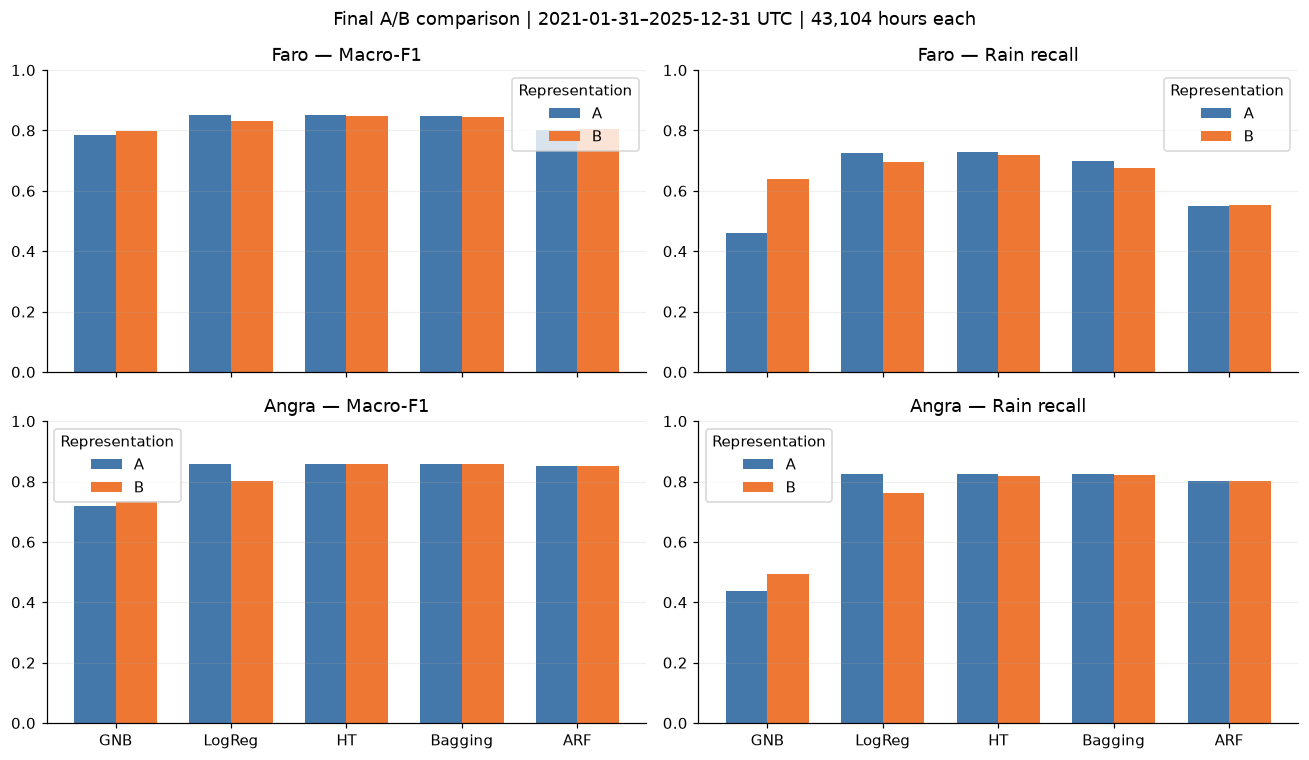

In [5]:
show_scores(final_metrics, extra=["evaluation_start", "evaluation_end"])
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for row, city in enumerate(CITIES):
    for col, metric in enumerate(["macro_f1", "recall"]):
        ax = axes[row, col]
        for offset, rep, color in [(-0.18, "A", "#4477AA"), (0.18, "B", "#EE7733")]:
            part = final_metrics.query("city == @city and representation == @rep").set_index("model").reindex(MODELS)
            ax.bar(np.arange(5) + offset, part[metric], width=0.36, color=color, label=rep)
        ax.set(title=f"{city} — {'Macro-F1' if metric == 'macro_f1' else 'Rain recall'}",
               ylim=(0, 1), xticks=np.arange(5), xticklabels=SHORT)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(title="Representation")
fig.suptitle("Final A/B comparison | 2021-01-31–2025-12-31 UTC | 43,104 hours each")
fig.tight_layout()
save_figure(fig, "predictive_comparison")

## 4. Confusion matrices

Rows are observed classes and columns are predicted classes. Each matrix is
`[[TN, FP], [FN, TP]]` and sums to 43,104. Counts, rather than normalized color
scales across cities, expose the contribution of each error type.

,city,representation,model,n_events,rain_hours,dry_hours,tn,fp,fn,tp,fallback_count
0,Faro,A,GaussianNB,43104,3802,39302,38996,306,2048,1754,0
1,Faro,A,LogisticRegression,43104,3802,39302,38278,1024,1040,2762,0
2,Faro,A,HoeffdingTree,43104,3802,39302,38271,1031,1035,2767,0
3,Faro,A,OnlineBagging,43104,3802,39302,38399,903,1144,2658,0
4,Faro,A,AdaptiveRandomForest,43104,3802,39302,38596,706,1716,2086,0
5,Faro,B,GaussianNB,43104,3802,39302,37888,1414,1375,2427,0
6,Faro,B,LogisticRegression,43104,3802,39302,38139,1163,1156,2646,0
7,Faro,B,HoeffdingTree,43104,3802,39302,38268,1034,1075,2727,0
8,Faro,B,OnlineBagging,43104,3802,39302,38473,829,1230,2572,0
9,Faro,B,AdaptiveRandomForest,43104,3802,39302,38599,703,1693,2109,0


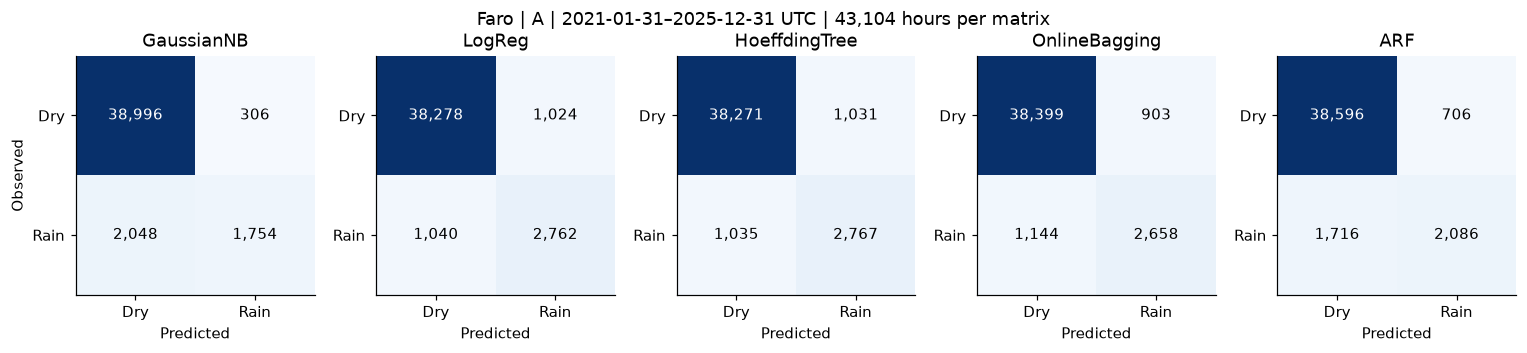

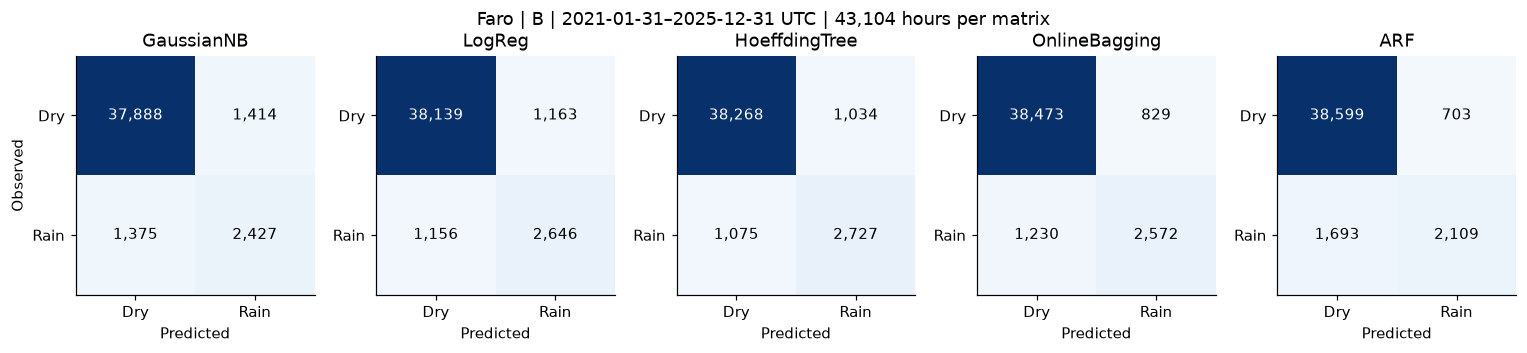

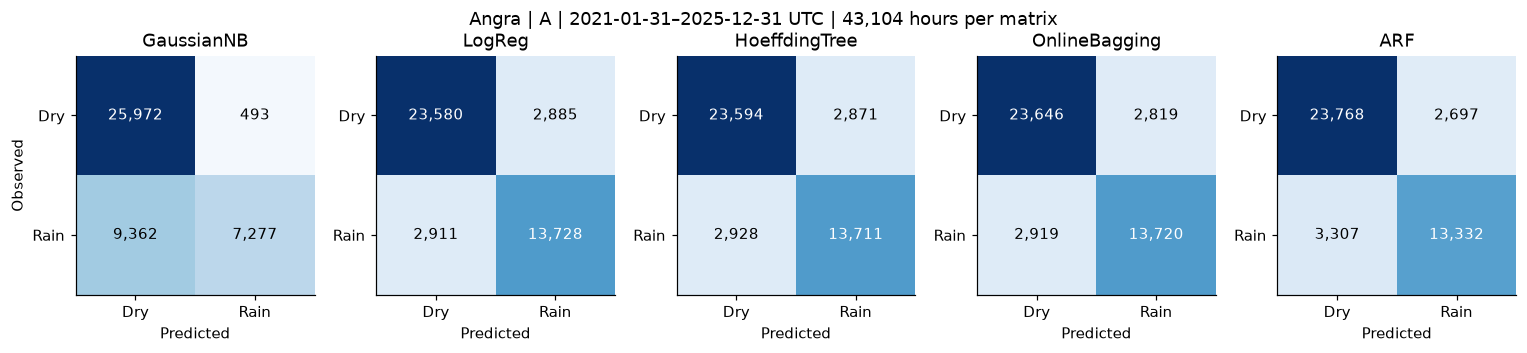

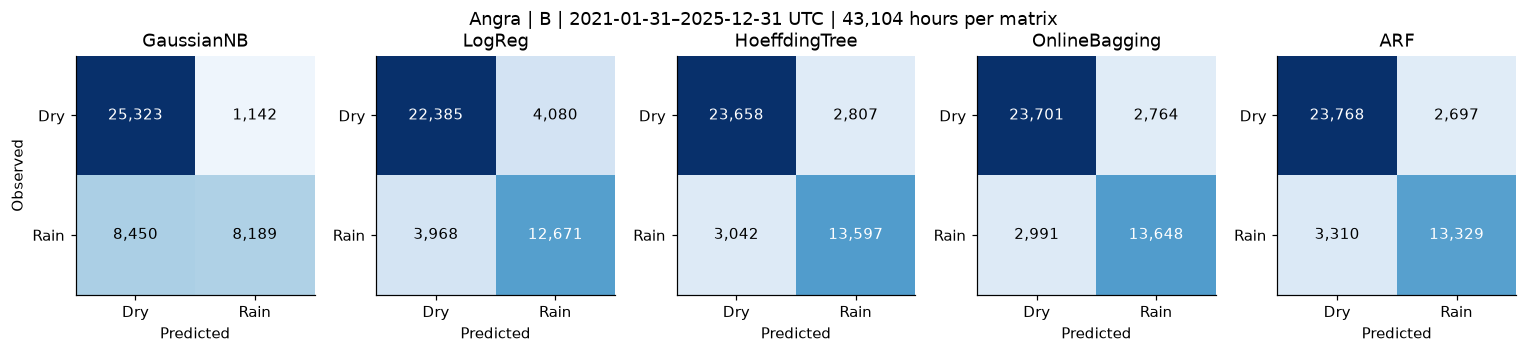

In [6]:
display(final_metrics[GROUPS + ["n_events", "rain_hours", "dry_hours", "tn", "fp", "fn", "tp", "fallback_count"]])
for city in CITIES:
    for rep in ["A", "B"]:
        part = final_metrics.query("city == @city and representation == @rep").set_index("model")
        fig, axes = plt.subplots(1, 5, figsize=(14, 3.0))
        for ax, name in zip(axes, MODELS):
            row = part.loc[name]
            matrix = np.array([[row.tn, row.fp], [row.fn, row.tp]], dtype=int)
            ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max())
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, f"{matrix[i,j]:,}", ha="center", va="center",
                            color="white" if matrix[i,j] > matrix.max() / 2 else "black")
            ax.set(title=name.replace("AdaptiveRandomForest", "ARF").replace("LogisticRegression", "LogReg"),
                   xticks=[0, 1], xticklabels=["Dry", "Rain"],
                   yticks=[0, 1], yticklabels=["Dry", "Rain"], xlabel="Predicted")
        axes[0].set_ylabel("Observed")
        fig.suptitle(f"{city} | {rep} | 2021-01-31–2025-12-31 UTC | 43,104 hours per matrix")
        fig.tight_layout()
        save_figure(fig, f"confusion_{city}_{rep}")

## 5. Computational cost

Mean wall-clock times measure `predict_one` and `learn_one` separately, using
`perf_counter`. Feature generation, file I/O, plotting and table aggregation are
excluded. The displayed final costs use the same 43,104 scored observations as
the predictive metrics. Full histories retain timings during warm-up too.
Times depend on hardware and system load.

,city,representation,model,n_events,prediction_us_per_hour,update_us_per_hour,prediction_seconds_total,update_seconds_total
0,Faro,A,GaussianNB,43104,91.736,3.565,3.954,0.154
1,Faro,A,LogisticRegression,43104,1.110,2.474,0.048,0.107
2,Faro,A,HoeffdingTree,43104,6.952,18.956,0.300,0.817
3,Faro,A,OnlineBagging,43104,74.907,200.082,3.229,8.624
4,Faro,A,AdaptiveRandomForest,43104,84.160,438.658,3.628,18.908
5,Faro,B,GaussianNB,43104,97.336,4.746,4.196,0.205
6,Faro,B,LogisticRegression,43104,1.239,3.141,0.053,0.135
7,Faro,B,HoeffdingTree,43104,7.973,26.523,0.344,1.143
8,Faro,B,OnlineBagging,43104,87.896,279.375,3.789,12.042
9,Faro,B,AdaptiveRandomForest,43104,84.916,496.288,3.660,21.392


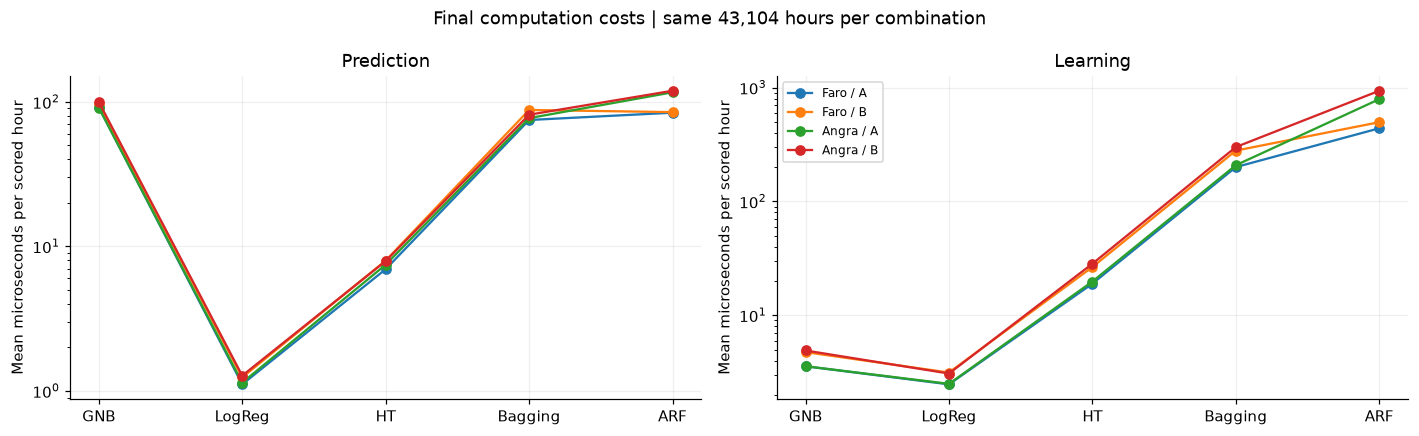

In [7]:
costs = final_metrics[GROUPS + ["n_events"]].copy()
costs["prediction_us_per_hour"] = final_metrics.prediction_time_per_event * 1e6
costs["update_us_per_hour"] = final_metrics.update_time_per_event * 1e6
costs["prediction_seconds_total"] = final_metrics.prediction_time_per_event * final_metrics.n_events
costs["update_seconds_total"] = final_metrics.update_time_per_event * final_metrics.n_events
display(costs.round(3))
costs.to_csv(OUTPUT / "computation_costs.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric, title in zip(axes, ["prediction_us_per_hour", "update_us_per_hour"], ["Prediction", "Learning"]):
    for index, ((city, rep), part) in enumerate(costs.groupby(["city", "representation"], sort=False)):
        values = part.set_index("model").reindex(MODELS)[metric]
        ax.plot(SHORT, values, marker="o", label=f"{city} / {rep}")
    ax.set(title=title, ylabel="Mean microseconds per scored hour", yscale="log")
    ax.grid(alpha=0.2)
axes[1].legend(fontsize=8)
fig.suptitle("Final computation costs | same 43,104 hours per combination")
fig.tight_layout()
save_figure(fig, "computation_costs")

## 6. Performance over time

Monthly partitions preserve UTC calendar boundaries and expose changes hidden
by aggregates. The first evaluated month contains only January 31, 2021.
Rain recall is undefined when a month has no rainy hours; those points are gaps.
Macro-F1 display values are also masked when only one observed class is present.
Detailed monthly supports and confusion counts are exported in
`final_monthly_metrics.csv`. Oscillations alone do not identify their cause.

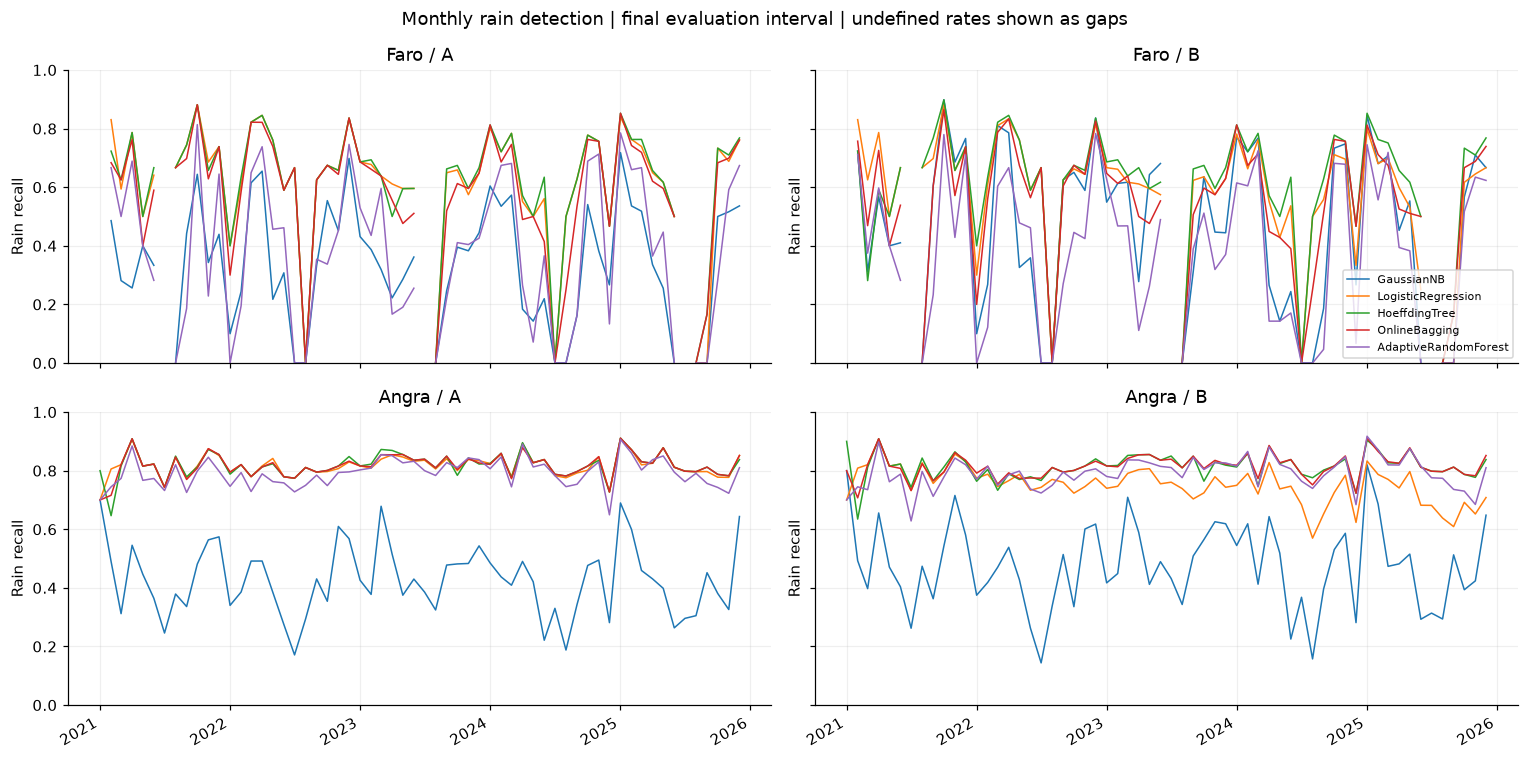

In [8]:
monthly = tables["final_monthly_metrics"]
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, sharey=True)
for row, city in enumerate(CITIES):
    for col, rep in enumerate(["A", "B"]):
        ax = axes[row, col]
        for name in MODELS:
            part = monthly.query("city == @city and representation == @rep and model == @name")
            ax.plot(pd.to_datetime(part.period), part.recall_display, label=name, color=COLORS[name], lw=1)
        ax.set(title=f"{city} / {rep}", ylabel="Rain recall", ylim=(0, 1))
        ax.grid(alpha=0.2)
axes[0, 1].legend(fontsize=7, loc="lower right")
fig.suptitle("Monthly rain detection | final evaluation interval | undefined rates shown as gaps")
fig.autofmt_xdate()
fig.tight_layout()
save_figure(fig, "monthly_recall")
assert monthly.groupby(GROUPS).n_events.sum().eq(43104).all()

## Conclusion

Over the final 43,104-hour evaluation interval, representation B did not
consistently improve on A. GaussianNB gained rain recall in both cities, while
logistic regression lost Macro-F1 and recall with B; the tree ensembles also
showed no uniform benefit. HoeffdingTree, logistic regression and Online Bagging
achieved similar aggregate Macro-F1 with A, but their computational costs
differed substantially. Logistic regression had the lowest measured prediction
and update costs, while the ensembles required more computation. Monthly recall
also varied, so aggregate scores should be read alongside class counts and
confusion matrices. These observed trade-offs do not establish statistical
superiority or determine a city's operational suitability.